In [1]:
%pip -q install scikit-learn opencv-python-headless

import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from sklearn.cluster import KMeans
from pathlib import Path
import time

print('OpenCV:', cv2.__version__)
print('NumPy:', np.__version__)

OpenCV: 4.14.0
NumPy: 2.1.3


In [4]:
K = 16
MAX_FIT_PIXELS = 100_000
RANDOM_STATE = 42
pixels = original_rgb.reshape(-1, 3).astype(np.float32)
if not isinstance(K, int) or K < 2 or K > len(pixels):
    raise ValueError(f'K must be an integer from 2 to {len(pixels):,}.')
rng = np.random.default_rng(RANDOM_STATE)
if len(pixels) > MAX_FIT_PIXELS:
    fit_pixels = pixels[rng.choice(len(pixels), MAX_FIT_PIXELS, replace=False)]
else:
    fit_pixels = pixels
start = time.time()
kmeans = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=10)
kmeans.fit(fit_pixels)
labels = kmeans.predict(pixels)
centroids = np.clip(np.rint(kmeans.cluster_centers_), 0, 255).astype(np.uint8)
compressed_rgb = centroids[labels].reshape(original_rgb.shape)
print(f'Fitted on {len(fit_pixels):,} pixels; assigned all {len(pixels):,} pixels.')
print(f'Palette colors: {len(np.unique(centroids, axis=0))} (requested K={K})')
print(f'Clustering and reconstruction: {time.time() - start:.1f} seconds')

Fitted on 100,000 pixels; assigned all 758,160 pixels.
Palette colors: 16 (requested K=16)
Clustering and reconstruction: 1.3 seconds


Saving Bird image.jpg to Bird image.jpg
Image dimensions: 720 × 1053 pixels


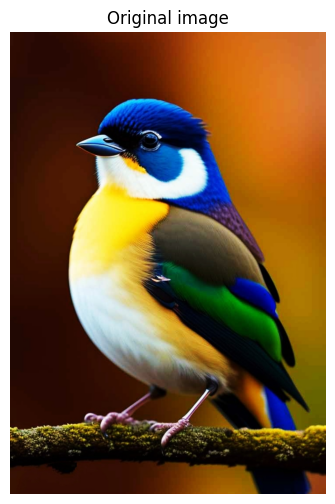

In [2]:
uploaded = files.upload()
if not uploaded:
    raise ValueError('Upload an image and run this cell again.')
filename = next(iter(uploaded))
image_path = Path(filename)
if image_path.suffix.lower() not in {'.jpg', '.jpeg', '.png'}:
    raise ValueError('Please upload a JPG, JPEG, or PNG image.')
image_bgr = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
if image_bgr is None:
    raise ValueError('OpenCV could not read this image.')
original_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
height, width, _ = original_rgb.shape
print(f'Image dimensions: {width} × {height} pixels')
plt.figure(figsize=(8, 6))
plt.imshow(original_rgb)
plt.title('Original image')
plt.axis('off');

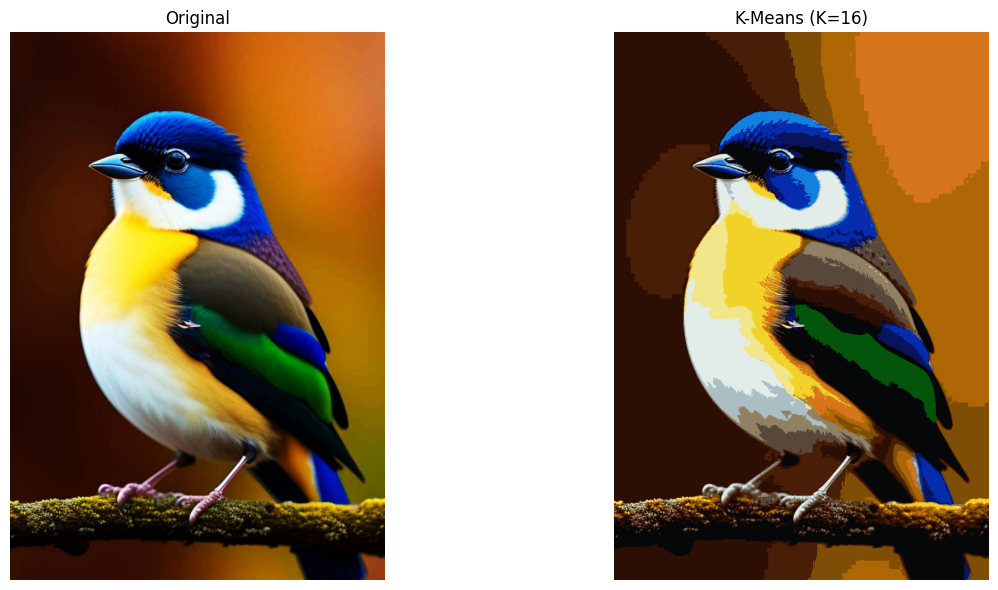

MSE: 185.35 (lower means closer pixel values)
PSNR: 25.45 dB (higher generally means closer pixel values)


In [5]:
difference = original_rgb.astype(np.float32) - compressed_rgb.astype(np.float32)
mse = float(np.mean(difference ** 2))
psnr = float('inf') if mse == 0 else 10 * np.log10((255 ** 2) / mse)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(original_rgb); axes[0].set_title('Original'); axes[0].axis('off')
axes[1].imshow(compressed_rgb); axes[1].set_title(f'K-Means (K={K})'); axes[1].axis('off')
plt.tight_layout(); plt.show()
print(f'MSE: {mse:.2f} (lower means closer pixel values)')
print(f'PSNR: {psnr:.2f} dB (higher generally means closer pixel values)')

In [6]:
extension = image_path.suffix.lower()
if extension == '.png':
    output_path = Path('compressed_kmeans.png')
    params = [cv2.IMWRITE_PNG_COMPRESSION, 3]
else:
    output_path = Path('compressed_kmeans.jpg')
    params = [cv2.IMWRITE_JPEG_QUALITY, 95]
original_bgr = cv2.cvtColor(original_rgb, cv2.COLOR_RGB2BGR)
compressed_bgr = cv2.cvtColor(compressed_rgb, cv2.COLOR_RGB2BGR)
ok1, original_encoded = cv2.imencode(extension, original_bgr, params)
ok2, compressed_encoded = cv2.imencode(extension, compressed_bgr, params)
if not ok1 or not ok2:
    raise RuntimeError('Could not encode the comparison images.')
original_comparison = Path(f'original_comparison{extension}')
original_comparison.write_bytes(original_encoded.tobytes())
output_path.write_bytes(compressed_encoded.tobytes())
source_size = image_path.stat().st_size
original_size = original_comparison.stat().st_size
compressed_size = output_path.stat().st_size
change_pct = (compressed_size - original_size) / original_size * 100
print(f'Uploaded source: {source_size:,} bytes ({source_size/1024:.1f} KiB)')
print(f'Original re-encoded ({extension.upper()}): {original_size:,} bytes ({original_size/1024:.1f} KiB)')
print(f'K-Means re-encoded ({extension.upper()}): {compressed_size:,} bytes ({compressed_size/1024:.1f} KiB)')
print(f'Size change vs same-format original: {change_pct:+.1f}%')
if compressed_size < original_size:
    print('Measured result: smaller for this image and these settings.')
elif compressed_size > original_size:
    print('Measured result: larger for this image and these settings.')
else:
    print('Measured result: the encoded files have the same size.')
files.download(str(output_path))

Uploaded source: 125,545 bytes (122.6 KiB)
Original re-encoded (.JPG): 114,129 bytes (111.5 KiB)
K-Means re-encoded (.JPG): 148,974 bytes (145.5 KiB)
Size change vs same-format original: +30.5%
Measured result: larger for this image and these settings.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>